# Classifying Audio, Then and Now

The radio archivist wants every hour of broadcast marked with its stretches of talk and music. The
labels "speech" and "music" become facets and filters: a journalist searches only the talk, a
music editor only the music. This notebook follows the book section *Classifying Audio*. It learns
a decision tree on two segment features from demo ch11-01, evaluates it honestly, and applies it to
a continuous stream and to whole files. Then it compares the tree with what replaced hand-crafted
features: AST, a pretrained network for 527 sound classes, and CLAP, which assigns labels it was
never trained on. At the end, CLAP answers text queries against the recordings of the chapter.

**Learning goals:**
- Learn a speech/music decision tree on LSTER and HZCRR and read its rules
- Evaluate a classifier on held-out recordings instead of held-out segments
- Turn segment labels into labels for a stream (smoothing) and for a file (voting)
- Label clips with a pretrained AudioSet classifier and with CLAP zero-shot prompts
- Search audio with a text query through CLAP embeddings

**Prerequisites:** demo ch11-01 (frames, segments, LSTER, HZCRR, log mel spectrum)

**Data:** the librosa example recordings of the chapter: three LibriVox readings, three music
pieces, a trumpet loop, a robin call, and a humpback whale song (downloaded on the first run). The
models AST (about 350 MB) and CLAP (about 600 MB) are downloaded from Hugging Face on first use and
run on a CPU.

## Setup

`segment_stats()` of `ch11_audio.py` computes LSTER and HZCRR of 4-second segments exactly as demo
ch11-01 built them step by step. `Clap` and `AudioTagger` wrap the two pretrained models.

In [1]:
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import train_test_split

from shared.display import print_table, display_md
from ch11_audio import SR, CLIPS, SPEECH_C, MUSIC_C, load, credits, segment_stats, Clap, AudioTagger

SPEECH = ["libri1", "libri2", "libri3"]
MUSIC = ["brahms", "nutcracker", "vibeace"]

## 1. Segment Features of Six Recordings

As in the book, we cut the longer music pieces to their first 45 seconds, so that no recording
dominates the training data, and compute LSTER and HZCRR for 4-second segments with a hop of
1 second. Label 0 stands for speech, 1 for music.

In [2]:
X, y, src = [], [], []
for label, names in ((0, SPEECH), (1, MUSIC)):
    for name in names:
        seg = segment_stats(load(name)[:45 * SR])       # (segments, 2): LSTER, HZCRR
        X.append(seg)
        y += [label] * len(seg)
        src += [name] * len(seg)
X, y, src = np.vstack(X), np.array(y), np.array(src)

rng = lambda v: f"{v.min():.2f} to {v.max():.2f} (mean {v.mean():.2f})"
print_table([[CLIPS[n][0], (src == n).sum(), rng(X[src == n, 0]), rng(X[src == n, 1])] for n in SPEECH + MUSIC],
            headers=["Recording", "Segments", "LSTER", "HZCRR"])

| Recording                                  |   Segments | LSTER                    | HZCRR                    |
|:-------------------------------------------|-----------:|:-------------------------|:-------------------------|
| LibriVox reading 1 (The Ashiel Mystery)    |         11 | 0.42 to 0.55 (mean 0.47) | 0.17 to 0.22 (mean 0.19) |
| LibriVox reading 2 (The Age of Chivalry)   |         13 | 0.41 to 0.66 (mean 0.51) | 0.13 to 0.20 (mean 0.16) |
| LibriVox reading 3 (Northanger Abbey)      |         10 | 0.43 to 0.62 (mean 0.53) | 0.15 to 0.19 (mean 0.18) |
| Brahms, Hungarian Dance No. 5              |         42 | 0.12 to 0.83 (mean 0.35) | 0.01 to 0.31 (mean 0.09) |
| Tchaikovsky, Dance of the Sugar Plum Fairy |         42 | 0.22 to 0.56 (mean 0.35) | 0.00 to 0.28 (mean 0.08) |
| Vibe Ace (jazz)                            |         42 | 0.30 to 0.52 (mean 0.40) | 0.14 to 0.31 (mean 0.19) |

## 2. A Decision Tree on Two Features

A decision tree classifies with a sequence of threshold tests. At each node, the learning algorithm
chooses the feature and the threshold that best separate the classes and repeats the choice in each
branch. We learn a tree of depth 2 with class weights that balance the 34 speech and 126 music
segments.

In [3]:
def fit_tree(X, y, depth=2):
    return DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=0).fit(X, y)

tree = fit_tree(X, y)
pred = tree.predict(X)
display_md("```text\n" + export_text(tree, feature_names=["LSTER", "HZCRR"], decimals=3,
                                     class_names=["speech", "music"]) + "```")

```text
|--- LSTER <= 0.410
|   |--- class: music
|--- LSTER >  0.410
|   |--- HZCRR <= 0.123
|   |   |--- class: music
|   |--- HZCRR >  0.123
|   |   |--- class: speech
```

The tree reads as two rules: if LSTER is at most 0.41, the segment is music; otherwise, if HZCRR is
at most 0.123, it is music, else speech.

In [4]:
print_table(
    [[CLIPS[n][0], f"{np.mean(pred[src == n] == y[src == n]):.1%}"] for n in SPEECH + MUSIC]
    + [["**all segments**", f"**{np.mean(pred == y):.1%}**"]],
    headers=["Recording", "Segments labeled correctly"],
)

| Recording                                  | Segments labeled correctly   |
|:-------------------------------------------|:-----------------------------|
| LibriVox reading 1 (The Ashiel Mystery)    | 100.0%                       |
| LibriVox reading 2 (The Age of Chivalry)   | 100.0%                       |
| LibriVox reading 3 (Northanger Abbey)      | 100.0%                       |
| Brahms, Hungarian Dance No. 5              | 88.1%                        |
| Tchaikovsky, Dance of the Sugar Plum Fairy | 81.0%                        |
| Vibe Ace (jazz)                            | 54.8%                        |
| **all segments**                           | **80.0%**                    |

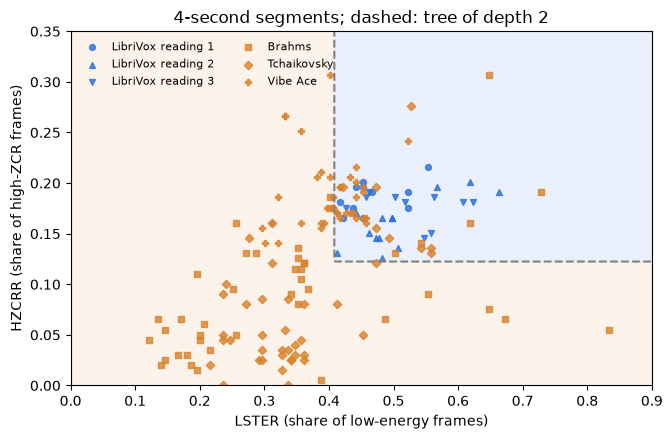

In [5]:
xx, yy = np.meshgrid(np.linspace(0, 1, 301), np.linspace(0, 0.5, 301))
Z = tree.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=[SPEECH_C, MUSIC_C], alpha=0.10)
ax.contour(xx, yy, Z, levels=[0.5], colors=["gray"], linestyles="--")
for name, marker in zip(SPEECH + MUSIC, "o^vsDP"):
    m = src == name
    ax.scatter(X[m, 0], X[m, 1], s=18, marker=marker, alpha=0.8, color=SPEECH_C if name in SPEECH else MUSIC_C,
               label=CLIPS[name][0].split(" (")[0].split(",")[0])
ax.set(xlabel="LSTER (share of low-energy frames)", ylabel="HZCRR (share of high-ZCR frames)",
       xlim=(0, 0.9), ylim=(0, 0.35), title="4-second segments; dashed: tree of depth 2")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
plt.show()

All speech segments are correct. The jazz piece Vibe Ace is the weak spot: its drum kit and
decaying vibraphone notes produce frames with many zero crossings and gaps of low energy, so many
of its segments fall into the speech region.

## 3. Held-Out Recordings, Not Held-Out Segments

The accuracy above is measured on the training segments. A common shortcut splits the segments at
random into training and test sets. But neighboring segments overlap by 3 seconds and come from the
same recording, so they are near duplicates, and a random split puts parts of the same recording
on both sides. The honest test holds out whole recordings: learn on five clips, test on the sixth.

In [6]:
random_acc = []
for seed in range(20):                                  # 20 random 70/30 splits of the segments
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
    random_acc.append(fit_tree(Xa, ya).score(Xb, yb))

rows, correct = [], 0
for name in SPEECH + MUSIC:
    held = src == name
    acc = fit_tree(X[~held], y[~held]).score(X[held], y[held])
    correct += acc * held.sum()
    rows.append([f"leave out {CLIPS[name][0]}", f"{acc:.1%}"])
rows += [["**random segment split** (mean of 20)", f"**{np.mean(random_acc):.1%}**"],
         ["**leave one recording out** (all segments)", f"**{correct / len(y):.1%}**"]]
print_table(rows, headers=["Test", "Accuracy"])

| Test                                                 | Accuracy   |
|:-----------------------------------------------------|:-----------|
| leave out LibriVox reading 1 (The Ashiel Mystery)    | 100.0%     |
| leave out LibriVox reading 2 (The Age of Chivalry)   | 76.9%      |
| leave out LibriVox reading 3 (Northanger Abbey)      | 100.0%     |
| leave out Brahms, Hungarian Dance No. 5              | 76.2%      |
| leave out Tchaikovsky, Dance of the Sugar Plum Fairy | 78.6%      |
| leave out Vibe Ace (jazz)                            | 54.8%      |
| **random segment split** (mean of 20)                | **79.2%**  |
| **leave one recording out** (all segments)           | **74.4%**  |

<div style="border-left: 4px solid #D97706; background: rgba(217, 119, 6, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#D97706; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Evaluate on held-out recordings</strong><br>
The random split reports an accuracy that new recordings do not reach. When a recording is held out completely, the tree must classify a reader or a piece it has never seen, and that is the situation of a real archive.
</div>

## 4. From Segments to a Stream

The archive needs labels for longer stretches. A test stream joins a second LibriVox reading,
20 seconds of Brahms, and a third reading. With a hop of 100 ms, the tree labels one 4-second
segment every tenth of a second.

In [7]:
a, b = load("libri2"), load("libri3")
stream = np.concatenate([a, load("brahms")[:20 * SR], b])
boundaries = [len(a) / SR, len(a) / SR + 20]            # the true changes

p = tree.predict(segment_stats(stream, hop_s=0.1))      # 1 = music
centers = np.arange(len(p)) * 0.1 + 2.0                 # time of each segment center
changes = centers[np.where(p[1:] != p[:-1])[0] + 1]
display_md(f"Stream of {len(stream) / SR:.1f} s, **{len(p)} segments**, true changes at "
           f"{boundaries[0]:.1f} s and {boundaries[1]:.1f} s. Raw label changes at segment centers: "
           + ", ".join(f"{c:.1f} s" for c in changes))

Stream of 50.7 s, **467 segments**, true changes at 16.7 s and 36.7 s. Raw label changes at segment centers: 7.1 s, 7.7 s, 9.6 s, 9.8 s, 16.7 s, 36.7 s

Smoothing adds up past predictions with decreasing weights. With the prediction $y(t) \in \{0, 1\}$
of segment $t$, the exponential average is

$$
s(t) = \alpha \cdot s(t-1) + (1 - \alpha) \cdot y(t)
$$

and the stream is labeled music while $s(t) > 0.5$.

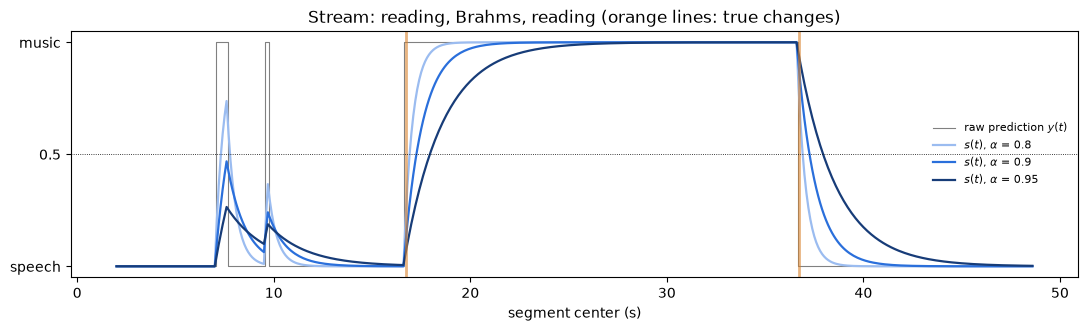

|   alpha |   Label changes | At segment centers           |
|--------:|----------------:|:-----------------------------|
|    0.8  |               4 | 7.4 s, 7.8 s, 17.0 s, 37.0 s |
|    0.9  |               2 | 17.3 s, 37.3 s               |
|    0.95 |               2 | 18.0 s, 38.0 s               |

In [8]:
def smooth(p, alpha):
    s, out = float(p[0]), []
    for v in p:
        s = alpha * s + (1 - alpha) * v
        out.append(s)
    return np.array(out)

fig, ax = plt.subplots(figsize=(13, 3.2))
ax.step(centers, p, where="mid", color="gray", lw=0.8, label="raw prediction $y(t)$")
rows = []
for alpha, color in ((0.8, "#9bbcf0"), (0.9, SPEECH_C), (0.95, "#173c78")):
    s = smooth(p, alpha)
    ch = centers[np.where((s[1:] > 0.5) != (s[:-1] > 0.5))[0] + 1]
    ax.plot(centers, s, color=color, lw=1.6, label=f"$s(t)$, $\\alpha$ = {alpha}")
    rows.append([alpha, len(ch), ", ".join(f"{c:.1f} s" for c in ch)])
for t in boundaries:
    ax.axvline(t, color=MUSIC_C, lw=2, alpha=0.6)
ax.axhline(0.5, color="black", lw=0.6, ls=":")
ax.set(xlabel="segment center (s)", yticks=[0, 0.5, 1], yticklabels=["speech", "0.5", "music"],
       title="Stream: reading, Brahms, reading (orange lines: true changes)")
ax.legend(frameon=False, fontsize=8, loc="center right")
plt.show()
print_table(rows, headers=["alpha", "Label changes", "At segment centers"])

With $\alpha = 0.9$, only the two real changes remain, a little more than half a second after the
true boundaries. A smaller $\alpha$ lets false switches survive, a larger one reacts more slowly.

For a single file, voting is simpler: the most frequent segment label wins.

In [9]:
rows = []
for name in ("brahms", "vibeace", "libri1"):
    votes = Counter(tree.predict(segment_stats(load(name)[:45 * SR])).tolist())
    rows.append([CLIPS[name][0], votes[0], votes[1], "music" if votes[1] > votes[0] else "speech"])
print_table(rows, headers=["File", "Speech segments", "Music segments", "Label"])

| File                                    |   Speech segments |   Music segments | Label   |
|:----------------------------------------|------------------:|-----------------:|:--------|
| Brahms, Hungarian Dance No. 5           |                 5 |               37 | music   |
| Vibe Ace (jazz)                         |                19 |               23 | music   |
| LibriVox reading 1 (The Ashiel Mystery) |                11 |                0 | speech  |

## 5. A Learned Classifier: AST on AudioSet

The tree knows two classes with features designed for these two classes. An archive needs many
more labels: applause, laughter, a crowd, a dog, rain. The Audio Spectrogram Transformer (AST) learns
its features from AudioSet, about two million ten-second clips with 527 sound classes. Its input is
the log mel spectrogram, treated like a single-channel image and cut into patches of 16 by 16 values.

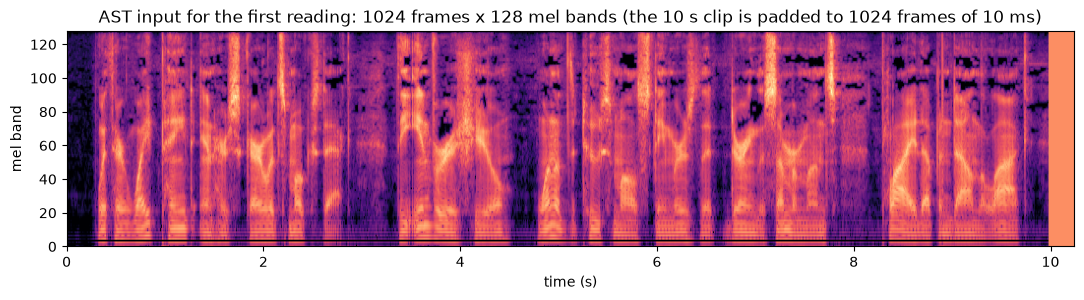

In [10]:
tagger = AudioTagger()
feats = tagger.features(load("libri1", 16000)[:10 * 16000])

fig, ax = plt.subplots(figsize=(13, 2.8))
ax.imshow(feats.T, origin="lower", aspect="auto", cmap="magma", extent=(0, feats.shape[0] / 100, 0, feats.shape[1]))
ax.set(xlabel="time (s)", ylabel="mel band", title=f"AST input for the first reading: {feats.shape[0]} frames x {feats.shape[1]} mel bands "
                                                         "(the 10 s clip is padded to 1024 frames of 10 ms)")
plt.show()

We apply AST to the first ten seconds of five clips (or the whole clip if it is shorter). Each
class has its own score between 0 and 1, because a clip can contain several sounds at once.

In [11]:
five = ["libri1", "brahms", "vibeace", "robin", "humpback"]
print_table([[CLIPS[n][0], ", ".join(f"{lab} {s:.2f}" for lab, s in tagger.top(load(n, 16000)[:10 * 16000]))]
             for n in five],
            headers=["Clip", "Top labels of AST"])

| Clip                                    | Top labels of AST                                                                               |
|:----------------------------------------|:------------------------------------------------------------------------------------------------|
| LibriVox reading 1 (The Ashiel Mystery) | Speech 0.83, Speech synthesizer 0.75, Narration, monologue 0.07, Male speech, man speaking 0.05 |
| Brahms, Hungarian Dance No. 5           | Music 0.79, Theme music 0.17, Background music 0.07, Orchestra 0.06                             |
| Vibe Ace (jazz)                         | Music 0.89, Ambient music 0.13, New-age music 0.11, Background music 0.09                       |
| Robin call                              | Chirp, tweet 0.42, Bird vocalization, bird call, bird song 0.34, Bird 0.32, Squawk 0.11         |
| Humpback whale, Glacier Bay             | Whale vocalization 0.60, Animal 0.44, Rain 0.20, Domestic animals, pets 0.11                    |

Vibe Ace, the weak spot of the tree, is clearly music, and the two animals get specific labels.
The score for "Speech synthesizer" on a human reader is a reminder that learned labels have errors
of their own.

## 6. CLAP: Zero-Shot Labels

A pretrained classifier knows only its 527 classes. CLAP trains an audio encoder and a text encoder
side by side on pairs of clips and their descriptions, so that clips and texts share one vector
space. To classify a clip, it embeds one prompt per label and applies a softmax over the
similarities, scaled by a learned temperature:

$$
P(\text{label}_i \mid \text{clip}) = \frac{\exp(\tau \cdot \cos(\mathbf{a}, \mathbf{t}_i))}{\sum_j \exp(\tau \cdot \cos(\mathbf{a}, \mathbf{t}_j))}
$$

In [12]:
clap = Clap()
names = SPEECH + MUSIC + ["robin", "humpback"]
A = clap.audio([load(n, Clap.SR)[:10 * Clap.SR] for n in names])     # one normalized row per clip

def zero_shot(A, labels, template="This is a sound of {}."):
    T = clap.text([template.format(l) for l in labels])
    logits = clap.scale * A @ T.T
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

labels = ["speech", "music", "applause", "a dog barking", "birdsong"]
P = zero_shot(A, labels)
print_table([[CLIPS[n][0]] + [f"**{v:.3f}**" if v == row.max() else f"{v:.3f}" for v in row]
             for n, row in zip(names, P)],
            headers=["Clip"] + labels)
display_md(f"Temperature $\\tau$ = {clap.scale:.2f}")

| Clip                                       | speech    | music     |   applause |   a dog barking | birdsong   |
|:-------------------------------------------|:----------|:----------|-----------:|----------------:|:-----------|
| LibriVox reading 1 (The Ashiel Mystery)    | **0.650** | 0.328     |      0.001 |           0.001 | 0.021      |
| LibriVox reading 2 (The Age of Chivalry)   | **0.824** | 0.126     |      0.001 |           0     | 0.050      |
| LibriVox reading 3 (Northanger Abbey)      | **0.830** | 0.110     |      0.002 |           0     | 0.058      |
| Brahms, Hungarian Dance No. 5              | 0.021     | **0.881** |      0.017 |           0.002 | 0.079      |
| Tchaikovsky, Dance of the Sugar Plum Fairy | 0.002     | **0.948** |      0.001 |           0.001 | 0.048      |
| Vibe Ace (jazz)                            | 0.003     | **0.990** |      0.001 |           0     | 0.006      |
| Robin call                                 | 0.000     | 0.000     |      0     |           0     | **0.999**  |
| Humpback whale, Glacier Bay                | 0.019     | **0.808** |      0.022 |           0.043 | 0.107      |

Temperature $\tau$ = 18.66

All six speech and music clips are labeled correctly, including Vibe Ace, and the robin is
recognized as birdsong without any training on these labels. The whale song is labeled music,
because none of the five prompts fits and a softmax always picks one of the offered labels.

The wording of the prompt matters too. With the bare words instead of the full sentence:

In [13]:
P_bare = zero_shot(A, labels, template="{}")
i = names.index("libri1")
print_table([["This is a sound of {}."] + [f"{v:.3f}" for v in P[i]], ["{}"] + [f"{v:.3f}" for v in P_bare[i]]],
            headers=["Prompt template, first reading"] + labels)

| Prompt template, first reading   |   speech |   music |   applause |   a dog barking |   birdsong |
|:---------------------------------|---------:|--------:|-----------:|----------------:|-----------:|
| This is a sound of {}.           |    0.65  |   0.328 |      0.001 |           0.001 |      0.021 |
| {}                               |    0.442 |   0.304 |      0     |           0     |      0.253 |

<div style="border-left: 4px solid #D97706; background: rgba(217, 119, 6, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#D97706; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">A zero-shot label is a choice among the offered labels</strong><br>
A high score means "closer than the other prompts", not "present in the clip". Include a catch-all prompt, or a threshold on the raw similarity, when the label set may not cover the content.
</div>

We add the catch-all prompt "This is a sound of something else." for the whale.

In [14]:
j = names.index("humpback")
labels_all = labels + ["something else"]
print_table([["Humpback whale"] + [f"{v:.3f}" for v in zero_shot(A[j:j + 1], labels_all)[0]]],
            headers=["Softmax with a catch-all"] + labels_all)

| Softmax with a catch-all   |   speech |   music |   applause |   a dog barking |   birdsong |   something else |
|:---------------------------|---------:|--------:|-----------:|----------------:|-----------:|-----------------:|
| Humpback whale             |    0.015 |   0.647 |      0.018 |           0.035 |      0.086 |            0.199 |

The catch-all prompt takes a share, but "music" still wins. Would a threshold on the raw cosine
similarity help? Here are the cosines of all clips with the five prompts, before the softmax:

In [15]:
cos = A @ clap.text([f"This is a sound of {l}." for l in labels]).T
print_table([[CLIPS[n][0]] + [f"{v:.3f}" for v in row] for n, row in zip(names, cos)],
            headers=["Cosine similarity"] + labels)

| Cosine similarity                          |   speech |   music |   applause |   a dog barking |   birdsong |
|:-------------------------------------------|---------:|--------:|-----------:|----------------:|-----------:|
| LibriVox reading 1 (The Ashiel Mystery)    |    0.377 |   0.341 |      0.003 |           0.001 |      0.194 |
| LibriVox reading 2 (The Age of Chivalry)   |    0.436 |   0.336 |      0.057 |          -0.007 |      0.286 |
| LibriVox reading 3 (Northanger Abbey)      |    0.43  |   0.322 |      0.105 |          -0.009 |      0.287 |
| Brahms, Hungarian Dance No. 5              |    0.093 |   0.294 |      0.082 |          -0.026 |      0.165 |
| Tchaikovsky, Dance of the Sugar Plum Fairy |    0.098 |   0.422 |      0.056 |           0.028 |      0.262 |
| Vibe Ace (jazz)                            |    0.207 |   0.526 |      0.153 |           0.059 |      0.254 |
| Robin call                                 |    0.159 |   0.177 |      0.166 |           0.094 |      0.599 |
| Humpback whale, Glacier Bay                |    0.196 |   0.397 |      0.204 |           0.24  |      0.289 |

Not here: the whale is more similar to "music" than the Brahms clip is. The prompts describe
categories that CLAP places loosely, and the whale song is musical. A label set that covers the
content, or a classifier with a class for whales such as AST, is the reliable fix.

## Payoff: Searching the Archive with Text

CLAP needs no classifier to search. A text query is embedded with the text encoder and compared
with the embeddings of all clips, the way a vector index answers a semantic text query. We add the
trumpet loop to the collection and send a few queries.

In [16]:
archive = names + ["trumpet"]
A_archive = np.vstack([A, clap.audio([load("trumpet", Clap.SR)])])

def search(query, k=3):
    sims = A_archive @ clap.text([query])[0]
    return [(archive[i], float(sims[i])) for i in np.argsort(sims)[::-1][:k]]

queries = ["a man reading a book aloud", "a woman reading a story", "an orchestra playing",
           "a trumpet solo", "drums and a vibraphone", "a bird singing", "a whale singing underwater"]
print_table([[q] + [f"{CLIPS[n][0].split(' (')[0]} ({s:.2f})" for n, s in search(q)] for q in queries],
            headers=["Query", "1st", "2nd", "3rd"])

| Query                      | 1st                                  | 2nd                                               | 3rd                                               |
|:---------------------------|:-------------------------------------|:--------------------------------------------------|:--------------------------------------------------|
| a man reading a book aloud | LibriVox reading 3 (0.25)            | LibriVox reading 2 (0.24)                         | LibriVox reading 1 (0.19)                         |
| a woman reading a story    | LibriVox reading 3 (0.33)            | LibriVox reading 2 (0.19)                         | Tchaikovsky, Dance of the Sugar Plum Fairy (0.18) |
| an orchestra playing       | Brahms, Hungarian Dance No. 5 (0.48) | Tchaikovsky, Dance of the Sugar Plum Fairy (0.39) | Vibe Ace (0.29)                                   |
| a trumpet solo             | Trumpet loop (0.61)                  | Tchaikovsky, Dance of the Sugar Plum Fairy (0.47) | Brahms, Hungarian Dance No. 5 (0.47)              |
| drums and a vibraphone     | Vibe Ace (0.57)                      | Tchaikovsky, Dance of the Sugar Plum Fairy (0.47) | Brahms, Hungarian Dance No. 5 (0.23)              |
| a bird singing             | Robin call (0.22)                    | Tchaikovsky, Dance of the Sugar Plum Fairy (0.10) | Humpback whale, Glacier Bay (0.10)                |
| a whale singing underwater | Humpback whale, Glacier Bay (0.45)   | Vibe Ace (0.23)                                   | LibriVox reading 2 (0.16)                         |

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Then and now</strong><br>
The tree needs two thresholds, a few dozen labeled segments, and runs on a microcontroller, but it knows two classes and confuses jazz with speech. AST knows 527 classes; CLAP labels and finds sounds for any text, without training for the label or the query. In the table above, most queries rank the right clip first. The miss is instructive: "a man reading" ranks the woman's reading first. The three readings get almost the same similarity, so the embedding separates reading from music far better than a male from a female voice.
</div>

## Summary

- A decision tree of depth 2 on LSTER and HZCRR separates speech from music with two readable rules;
  it fails on music with drums and pauses.
- Overlapping segments of one recording are near duplicates. Hold out whole recordings to measure
  how a classifier does on new material.
- Smoothing turns noisy segment labels into stretches of a stream; voting labels a whole file.
- AST learns features from the log mel spectrogram and knows the 527 AudioSet classes. CLAP compares
  clips with text prompts, so it labels and searches without a trained classifier, but a softmax
  always picks one of the offered labels.

## Try it yourself

1. **A deeper tree.** Learn trees of depth 1, 3, and 5 and compare the training accuracy with the
   leave-one-recording-out accuracy. Which depth generalizes best?
2. **Smoothing.** Rerun section 4 with `alpha = 0.85` and `0.97`. How do the number of false switches
   and the delay change?
3. **Your own prompts.** Add labels such as "a crowd cheering" or "rain" to the zero-shot table, or
   send your own queries to `search()`. Which wordings work best?

## Credits

In [17]:
print_table(credits(archive), headers=["Clip", "Title", "Attribution", "License"])

| Clip       | Title                                                                  | Attribution                                             | License    |
|:-----------|:-----------------------------------------------------------------------|:--------------------------------------------------------|:-----------|
| libri1     | The Ashiel Mystery                                                     | Marion Bryce (author), Garth Comira (reader)            | CC-BY-4.0  |
| libri2     | The Age of Chivalry, chapter IX: The Adventure of the Cart             | Thomas Bulfinch (author), Anders Lankford (reader)      | CC-BY-4.0  |
| libri3     | Northanger Abbey (librosa metadata: Sense and Sensibility, chapter 18) | Jane Austen (author), Heather Barnett (reader)          | CC-BY-4.0  |
| brahms     | Hungarian Dance number 5                                               | Johannes Brahms (composer), US Army Strings (performer) | CC-PDM-1.0 |
| nutcracker | Dance of the Sugar Plum Fairy                                          | P.I. Tchaikovsky (composer), Kevin MacLeod (arranger)   | CC-BY-4.0  |
| vibeace    | Vibe Ace                                                               | Kevin MacLeod                                           | CC-BY-4.0  |
| robin      | Bird Whistling, Robin, Single, 13.wav                                  | InspectorJ                                              | CC-BY-4.0  |
| humpback   | Glacier Bay                                                            | Recorded by NPS - Chris Gabriele                        | CC-PDM-1.0 |
| trumpet    | solo trumpet 06                                                        | Mihai Sorohan                                           | CC-BY-4.0  |